# ADY201m Churn EDA

EDA notebook. Uses `DATA_RAW_FILE` as the main business-readable EDA source and writes EDA outputs only under `Source/reports/`.


In [1]:
import sys
from io import StringIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Make package imports work whether the notebook is run from the repository root or Source/notebooks.
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(
    path for path in (CURRENT_DIR, *CURRENT_DIR.parents)
    if (path / "Source" / "src").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Source.src.path import DATA_RAW_FILE, DATA_REPORTS_DIR, FIGURES_DIR
from Source.src.utils.feature_display import (
    get_category_display_name,
    get_feature_display_name,
)

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

DATA_REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("EDA data source DATA_RAW_FILE:", DATA_RAW_FILE)
print("Figure output folder:", FIGURES_DIR)
print("Table output folder:", DATA_REPORTS_DIR)


Project root: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1
EDA data source DATA_RAW_FILE: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\raw_data\data_raw.csv
Figure output folder: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures
Table output folder: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports


## Load Data And Sanity Checks


In [2]:
df = pd.read_csv(DATA_RAW_FILE)

print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Column names:")
print(df.columns.tolist())
display(df.head())

info_buffer = StringIO()
df.info(buf=info_buffer)
print("DataFrame info:")
print(info_buffer.getvalue())

missing_values_summary = (
    df.isna().sum()
    .rename("missing_count")
    .reset_index()
    .rename(columns={"index": "column"})
)
missing_values_summary["missing_percent"] = (
    missing_values_summary["missing_count"] / len(df) * 100
).round(2)
missing_values_summary = missing_values_summary.sort_values(
    ["missing_count", "column"], ascending=[False, True]
)
print("Missing-value summary shape:", missing_values_summary.shape)
display(missing_values_summary)

print("Duplicate row count:", df.duplicated().sum())

if "Churn" not in df.columns:
    raise ValueError("Required EDA target column 'Churn' is missing from DATA_RAW_FILE.")

print("Churn value counts:")
display(df["Churn"].value_counts(dropna=False).rename("count").reset_index().rename(columns={"index": "Churn"}))


Shape: (7043, 20)
Rows: 7043
Columns: 20
Column names:
['ID', 'Churn', 'SeniorCitizen', 'Partner', 'Dependents', 'Tenure', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'tenure_group', 'service_diversity', 'monthly_charges_ratio', 'is_paperless_electronic']


,ID,Churn,SeniorCitizen,Partner,Dependents,Tenure,Contract,PaymentMethod,PaperlessBilling,MonthlyCharges,TotalCharges,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,tenure_group,service_diversity,monthly_charges_ratio,is_paperless_electronic
0,0002-ORFBO,0,0,1,No,9,12,Mailed check,1,65.6,593.30,DSL,0,1,0,1,0-12 months,2,1.012944,0
1,0003-MKNFE,0,0,0,No,9,1,Mailed check,0,59.9,542.40,DSL,0,0,0,0,0-12 months,0,0.924930,0
2,0004-TLHLJ,1,0,0,No,4,1,Electronic check,1,73.9,280.85,Fiber optic,0,0,1,0,0-12 months,1,1.141107,0
3,0011-IGKFF,1,1,1,No,13,1,Electronic check,1,98.0,1237.85,Fiber optic,0,1,1,0,13-24 months,2,1.513240,0
4,0013-EXCHZ,1,1,1,No,3,1,Mailed check,1,83.9,267.40,Fiber optic,0,0,0,1,0-12 months,1,1.295519,0


DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       7043 non-null   object 
 1   Churn                    7043 non-null   int64  
 2   SeniorCitizen            7043 non-null   int64  
 3   Partner                  7043 non-null   int64  
 4   Dependents               7043 non-null   object 
 5   Tenure                   7043 non-null   int64  
 6   Contract                 7043 non-null   int64  
 7   PaymentMethod            7043 non-null   object 
 8   PaperlessBilling         7043 non-null   int64  
 9   MonthlyCharges           7043 non-null   float64
 10  TotalCharges             7043 non-null   float64
 11  InternetService          7043 non-null   object 
 12  OnlineSecurity           7043 non-null   int64  
 13  OnlineBackup             7043 non-null   int64  
 14  DevicePr

,column,missing_count,missing_percent
1,Churn,0,0.0
6,Contract,0,0.0
4,Dependents,0,0.0
14,DeviceProtection,0,0.0
0,ID,0,0.0
11,InternetService,0,0.0
9,MonthlyCharges,0,0.0
13,OnlineBackup,0,0.0
12,OnlineSecurity,0,0.0
8,PaperlessBilling,0,0.0


Duplicate row count: 0
Churn value counts:


,Churn,count
0,0,5174
1,1,1869


In [3]:
def normalize_churn_value(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, str):
        normalized = value.strip().lower()
        if normalized in {"1", "yes", "y", "true", "churn"}:
            return 1
        if normalized in {"0", "no", "n", "false", "non-churn", "non churn"}:
            return 0
    if isinstance(value, (bool, np.bool_)):
        return int(value)
    if isinstance(value, (int, float, np.integer, np.floating)):
        if value == 1:
            return 1
        if value == 0:
            return 0
    return np.nan


CHURN_LABEL_ORDER = [
    get_category_display_name("Churn", 0),
    get_category_display_name("Churn", 1),
]
CHURN_PALETTE = {
    get_category_display_name("Churn", 0): "#59a14f",
    get_category_display_name("Churn", 1): "#e15759",
}


df_eda = df.copy()
df_eda["_churn_num"] = df_eda["Churn"].map(normalize_churn_value)
unknown_churn = df_eda[df_eda["_churn_num"].isna()]["Churn"].dropna().unique().tolist()
if unknown_churn:
    raise ValueError(f"Churn contains values that cannot be mapped to 0/1: {unknown_churn}")
if df_eda["_churn_num"].isna().any():
    raise ValueError("Churn contains missing values after target normalization.")

df_eda["_churn_label"] = df_eda["_churn_num"].map(
    lambda value: get_category_display_name("Churn", value)
)
churn_rate = df_eda["_churn_num"].mean()
print("Churn rate:", f"{churn_rate:.2%}")


Churn rate: 26.54%


## Helper Functions


In [4]:
def has_columns(columns):
    missing = [column for column in columns if column not in df_eda.columns]
    if missing:
        print(f"WARNING: Missing columns {missing}; skipping dependent output.")
        return False
    return True


def save_table(table_df, filename):
    output_path = DATA_REPORTS_DIR / filename
    print(f"Table shape for {filename}:", table_df.shape)
    display(table_df)
    table_df.to_csv(output_path, index=False)
    print("Saved table path:", output_path)
    return output_path


def save_figure(filename):
    output_path = FIGURES_DIR / filename
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight", facecolor="white")
    print("Saved figure path:", output_path)
    plt.show()
    return output_path


def build_category_display_series(column, values):
    return pd.Series(values).map(lambda value: get_category_display_name(column, value))


def churn_rate_table(column, filename):
    if not has_columns([column]):
        return None
    table = (
        df_eda.groupby(column, dropna=False)["_churn_num"]
        .agg(count="size", churn_count="sum", churn_rate="mean")
        .reset_index()
    )
    table["feature_code"] = column
    table["feature_display_name"] = get_feature_display_name(column)
    table["category_code"] = table[column]
    table["category_display_name"] = build_category_display_series(column, table[column])
    table["churn_rate_pct"] = (table["churn_rate"] * 100).round(2)
    table = table.sort_values(["churn_rate", "count"], ascending=[False, False])
    table = table[
        [
            "feature_code",
            "feature_display_name",
            "category_code",
            "category_display_name",
            "count",
            "churn_count",
            "churn_rate",
            "churn_rate_pct",
        ]
    ]
    return save_table(table, filename)


def plot_churn_rate_bar(column, title, filename):
    if not has_columns([column]):
        return None
    plot_df = (
        df_eda.groupby(column, dropna=False)["_churn_num"]
        .mean()
        .mul(100)
        .rename("churn_rate_pct")
        .reset_index()
        .sort_values("churn_rate_pct", ascending=False)
    )
    plot_df["category_display_name"] = build_category_display_series(column, plot_df[column])
    feature_display_name = get_feature_display_name(column)
    plt.figure(figsize=(11, 6))
    ax = sns.barplot(data=plot_df, x="category_display_name", y="churn_rate_pct", color="#4c78a8")
    ax.set_title(title or f"Churn Rate by {feature_display_name}")
    ax.set_xlabel(feature_display_name)
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=35)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
    return save_figure(filename)


def plot_churn_rate_heatmap(row_col, col_col, title, filename):
    if not has_columns([row_col, col_col]):
        return None
    pivot = df_eda.pivot_table(
        values="_churn_num",
        index=row_col,
        columns=col_col,
        aggfunc="mean",
        observed=False,
    ) * 100
    pivot.index = [get_category_display_name(row_col, value) for value in pivot.index]
    pivot.columns = [get_category_display_name(col_col, value) for value in pivot.columns]
    plt.figure(figsize=(12, 7))
    ax = sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", linewidths=0.5)
    ax.set_title(title)
    ax.set_xlabel(get_feature_display_name(col_col))
    ax.set_ylabel(get_feature_display_name(row_col))
    return save_figure(filename)


## Required EDA Tables


In [5]:
overview_table = pd.DataFrame({
    "metric": [
        "rows",
        "columns",
        "duplicate_rows",
        "churn_count",
        "non_churn_count",
        "churn_rate",
        "data_source",
    ],
    "value": [
        df_eda.shape[0],
        df_eda.shape[1] - 2,  # exclude notebook-local helper columns
        int(df.duplicated().sum()),
        int(df_eda["_churn_num"].sum()),
        int((df_eda["_churn_num"] == 0).sum()),
        round(float(churn_rate), 4),
        str(DATA_RAW_FILE),
    ],
})
save_table(overview_table, "eda_dataset_overview.csv")
save_table(missing_values_summary, "eda_missing_values_summary.csv")

numeric_summary = df.select_dtypes(include=[np.number]).describe().T.reset_index().rename(columns={"index": "column"})
save_table(numeric_summary, "eda_numeric_summary.csv")


Table shape for eda_dataset_overview.csv: (7, 2)


,metric,value
0,rows,7043
1,columns,20
2,duplicate_rows,0
3,churn_count,1869
4,non_churn_count,5174
5,churn_rate,0.2654
6,data_source,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...


Saved table path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\eda_dataset_overview.csv
Table shape for eda_missing_values_summary.csv: (20, 3)


,column,missing_count,missing_percent
1,Churn,0,0.0
6,Contract,0,0.0
4,Dependents,0,0.0
14,DeviceProtection,0,0.0
0,ID,0,0.0
11,InternetService,0,0.0
9,MonthlyCharges,0,0.0
13,OnlineBackup,0,0.0
12,OnlineSecurity,0,0.0
8,PaperlessBilling,0,0.0


Saved table path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\eda_missing_values_summary.csv
Table shape for eda_numeric_summary.csv: (15, 9)


,column,count,mean,std,min,25%,50%,75%,max
0,Churn,7043.0,0.265370,0.441561,0.000000,0.000000,0.00000,1.000000,1.000000
1,SeniorCitizen,7043.0,0.162147,0.368612,0.000000,0.000000,0.00000,0.000000,1.000000
2,Partner,7043.0,0.483033,0.499748,0.000000,0.000000,0.00000,1.000000,1.000000
3,Tenure,7043.0,32.371149,24.559481,0.000000,9.000000,29.00000,55.000000,72.000000
4,Contract,7043.0,8.835865,9.551444,1.000000,1.000000,1.00000,12.000000,24.000000
5,PaperlessBilling,7043.0,0.592219,0.491457,0.000000,0.000000,1.00000,1.000000,1.000000
6,MonthlyCharges,7043.0,64.761692,30.090047,18.250000,35.500000,70.35000,89.850000,118.750000
7,TotalCharges,7043.0,2279.734304,2266.794470,0.000000,398.550000,1394.55000,3786.600000,8684.800000
8,OnlineSecurity,7043.0,0.286668,0.452237,0.000000,0.000000,0.00000,1.000000,1.000000
9,OnlineBackup,7043.0,0.344881,0.475363,0.000000,0.000000,0.00000,1.000000,1.000000


Saved table path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\eda_numeric_summary.csv


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/eda_numeric_summary.csv')

In [6]:
churn_rate_table("Contract", "eda_churn_rate_by_contract.csv")
churn_rate_table("PaymentMethod", "eda_churn_rate_by_payment_method.csv")
churn_rate_table("InternetService", "eda_churn_rate_by_internet_service.csv")
churn_rate_table("tenure_group", "eda_churn_rate_by_tenure_group.csv")
churn_rate_table("service_diversity", "eda_churn_rate_by_service_diversity.csv")
churn_rate_table("TechSupport", "eda_churn_rate_by_tech_support.csv")
churn_rate_table("OnlineSecurity", "eda_churn_rate_by_online_security.csv")
churn_rate_table("PaperlessBilling", "eda_churn_rate_by_paperless_billing.csv")
churn_rate_table("SeniorCitizen", "eda_churn_rate_by_senior_citizen.csv")
churn_rate_table("Partner", "eda_churn_rate_by_partner.csv")
churn_rate_table("Dependents", "eda_churn_rate_by_dependents.csv")


Table shape for eda_churn_rate_by_contract.csv: (3, 5)


,Contract,total_count,churn_count,churn_rate,churn_rate_pct
0,1,3875,1655,0.427097,42.71
1,12,1473,166,0.112695,11.27
2,24,1695,48,0.028319,2.83


Saved table path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\eda_churn_rate_by_contract.csv
Table shape for eda_churn_rate_by_payment_method.csv: (4, 5)


,PaymentMethod,total_count,churn_count,churn_rate,churn_rate_pct
2,Electronic check,2365,1071,0.452854,45.29
3,Mailed check,1612,308,0.191067,19.11
0,Bank transfer (automatic),1544,258,0.167098,16.71
1,Credit card (automatic),1522,232,0.152431,15.24


Saved table path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\eda_churn_rate_by_payment_method.csv
Table shape for eda_churn_rate_by_internet_service.csv: (3, 5)


,InternetService,total_count,churn_count,churn_rate,churn_rate_pct
1,Fiber optic,3096,1297,0.418928,41.89
0,DSL,2421,459,0.189591,18.96
2,No,1526,113,0.074050,7.40


... (14 outputs left out)

Saved table path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\eda_churn_rate_by_partner.csv
Table shape for eda_churn_rate_by_dependents.csv: (2, 5)


,Dependents,total_count,churn_count,churn_rate,churn_rate_pct
0,No,5416,1763,0.325517,32.55
1,Yes,1627,106,0.065151,6.52


Saved table path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\eda_churn_rate_by_dependents.csv


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/eda_churn_rate_by_dependents.csv')

In [7]:
risk_candidates = [
    "Contract",
    "PaymentMethod",
    "InternetService",
    "TechSupport",
    "tenure_group",
    "service_diversity",
]
if "monthly_charges_ratio" in df_eda.columns:
    df_eda["_monthly_charges_ratio_group"] = pd.qcut(
        df_eda["monthly_charges_ratio"],
        q=4,
        duplicates="drop",
    ).astype(str)
    risk_candidates.append("_monthly_charges_ratio_group")

risk_frames = []
for column in risk_candidates:
    if column not in df_eda.columns:
        print(f"WARNING: Missing column {column}; skipping it in top risk segments.")
        continue
    segment_table = (
        df_eda.groupby(column, dropna=False)["_churn_num"]
        .agg(total_count="size", churn_count="sum", churn_rate="mean")
        .reset_index()
        .rename(columns={column: "segment"})
    )
    segment_table["feature"] = column
    segment_table["feature_display_name"] = get_feature_display_name(column)
    segment_table["segment_display_name"] = build_category_display_series(column, segment_table["segment"])
    segment_table["feature_segment_display"] = (
        segment_table["feature_display_name"].astype(str)
        + " = "
        + segment_table["segment_display_name"].astype(str)
    )
    risk_frames.append(segment_table)

if risk_frames:
    top_risk_segments = pd.concat(risk_frames, ignore_index=True)
    top_risk_segments["churn_rate_pct"] = (top_risk_segments["churn_rate"] * 100).round(2)
    top_risk_segments = top_risk_segments.sort_values(
        ["churn_rate", "total_count"], ascending=[False, False]
    )
    save_table(top_risk_segments, "eda_top_risk_segments.csv")
else:
    print("WARNING: No risk segment columns were available; eda_top_risk_segments.csv was not exported.")


Table shape for eda_top_risk_segments.csv: (27, 6)


,segment,total_count,churn_count,churn_rate,feature,churn_rate_pct
12,0-12 months,2186,1037,0.474382,tenure_group,47.44
5,Electronic check,2365,1071,0.452854,PaymentMethod,45.29
0,1,3875,1655,0.427097,Contract,42.71
8,Fiber optic,3096,1297,0.418928,InternetService,41.89
19,1,1467,570,0.388548,service_diversity,38.85
25,"(1.086, 1.387]",1757,659,0.375071,_monthly_charges_ratio_group,37.51
26,"(1.387, 1.834]",1758,578,0.328783,_monthly_charges_ratio_group,32.88
10,0,4999,1559,0.311862,TechSupport,31.19
18,0,2793,831,0.297530,service_diversity,29.75
13,13-24 months,1024,294,0.287109,tenure_group,28.71


Saved table path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\eda_top_risk_segments.csv


In [8]:
numeric_for_corr = df.select_dtypes(include=[np.number]).copy()
if "ID" in numeric_for_corr.columns:
    numeric_for_corr = numeric_for_corr.drop(columns=["ID"])
if "Churn" not in numeric_for_corr.columns:
    numeric_for_corr["Churn"] = df_eda["_churn_num"]

if numeric_for_corr.shape[1] >= 2:
    correlation_matrix = numeric_for_corr.corr()
    correlation_display_matrix = correlation_matrix.rename(
        index=get_feature_display_name,
        columns=get_feature_display_name,
    )
    correlation_table = correlation_matrix.reset_index().rename(columns={"index": "feature"})
    correlation_table.insert(
        1,
        "feature_display_name",
        correlation_table["feature"].map(get_feature_display_name),
    )
    save_table(correlation_table, "eda_correlation_matrix.csv")
else:
    print("WARNING: Fewer than two numeric columns available; eda_correlation_matrix.csv was not exported.")


Table shape for eda_correlation_matrix.csv: (15, 16)


,feature,Churn,SeniorCitizen,Partner,Tenure,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,service_diversity,monthly_charges_ratio,is_paperless_electronic
0,Churn,1.000000,0.150889,-0.150448,-0.352229,-0.394453,0.191825,0.193356,-0.198324,-0.171226,-0.082255,-0.066160,-0.164674,-0.173061,0.193356,-0.086320
1,SeniorCitizen,0.150889,1.000000,0.016479,0.016567,-0.142117,0.156530,0.220173,0.103006,-0.038653,0.066572,0.059428,-0.060625,0.011562,0.220173,0.028858
2,Partner,-0.150448,0.016479,1.000000,0.379697,0.294178,-0.014877,0.096848,0.317504,0.143106,0.141498,0.153786,0.119999,0.201652,0.096848,0.105783
3,Tenure,-0.352229,0.016567,0.379697,1.000000,0.669877,0.006152,0.247900,0.826178,0.327203,0.360277,0.360653,0.324221,0.495557,0.247900,0.263205
4,Contract,-0.394453,-0.142117,0.294178,0.669877,1.000000,-0.176319,-0.074584,0.444937,0.244341,0.153899,0.217971,0.292782,0.326444,-0.074584,0.135746
5,PaperlessBilling,0.191825,0.156530,-0.014877,0.006152,-0.176319,1.000000,0.352150,0.158574,-0.003636,0.126735,0.103797,0.037880,0.097213,0.352150,0.481306
6,MonthlyCharges,0.193356,0.220173,0.096848,0.247900,-0.074584,0.352150,1.000000,0.651174,0.296594,0.441780,0.482692,0.338304,0.564924,1.000000,0.200437
7,TotalCharges,-0.198324,0.103006,0.317504,0.826178,0.444937,0.158574,0.651174,1.000000,0.411651,0.509226,0.521983,0.431883,0.677781,0.651174,0.297995
8,OnlineSecurity,-0.171226,-0.038653,0.143106,0.327203,0.244341,-0.003636,0.296594,0.411651,1.000000,0.283832,0.275438,0.354931,0.683129,0.296594,0.127860
9,OnlineBackup,-0.082255,0.066572,0.141498,0.360277,0.153899,0.126735,0.441780,0.509226,0.283832,1.000000,0.303546,0.294233,0.684967,0.441780,0.172424


Saved table path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\eda_correlation_matrix.csv


## Required EDA Charts


C:\Users\HGB\AppData\Local\Temp\ipykernel_15112\113846444.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_eda, x="_churn_label", order=["Non-Churn", "Churn"], palette=["#59a14f", "#e15759"])


Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_01_churn_distribution.png


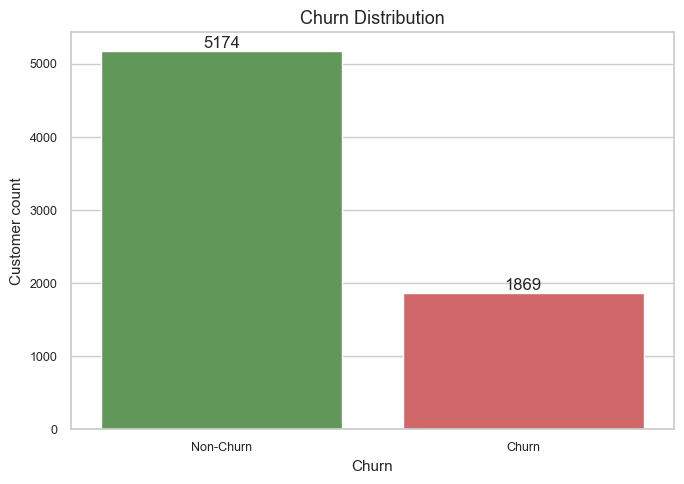

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/eda_01_churn_distribution.png')

In [9]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(
    data=df_eda,
    x="_churn_label",
    order=CHURN_LABEL_ORDER,
    palette=[CHURN_PALETTE[label] for label in CHURN_LABEL_ORDER],
)
ax.set_title("Churn Distribution")
ax.set_xlabel(get_feature_display_name("Churn"))
ax.set_ylabel("Customer count")
for container in ax.containers:
    ax.bar_label(container)
save_figure("eda_01_churn_distribution.png")


Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_02_churn_rate_by_contract.png


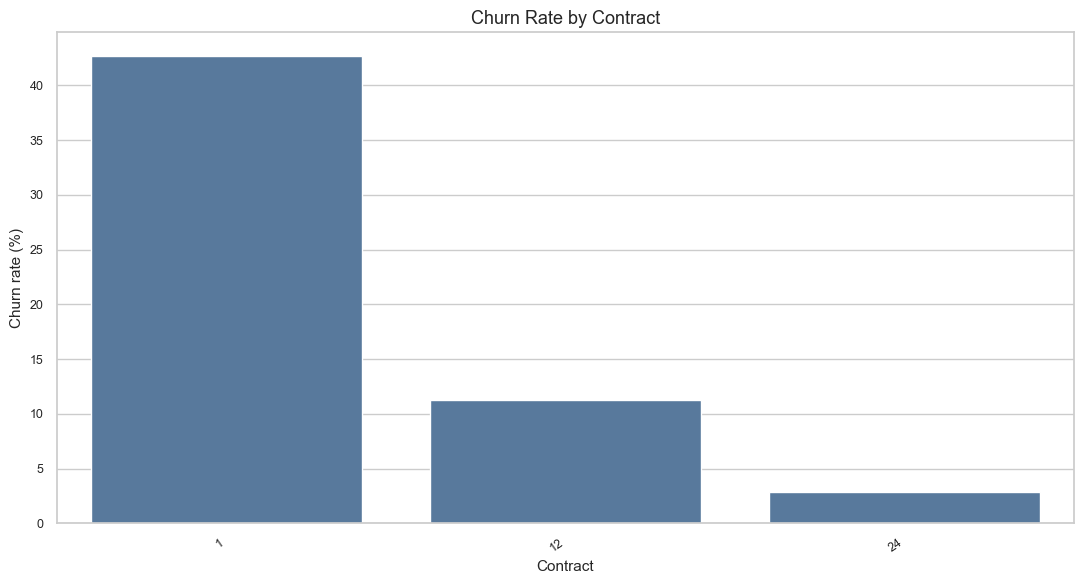

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_03_churn_rate_by_payment_method.png


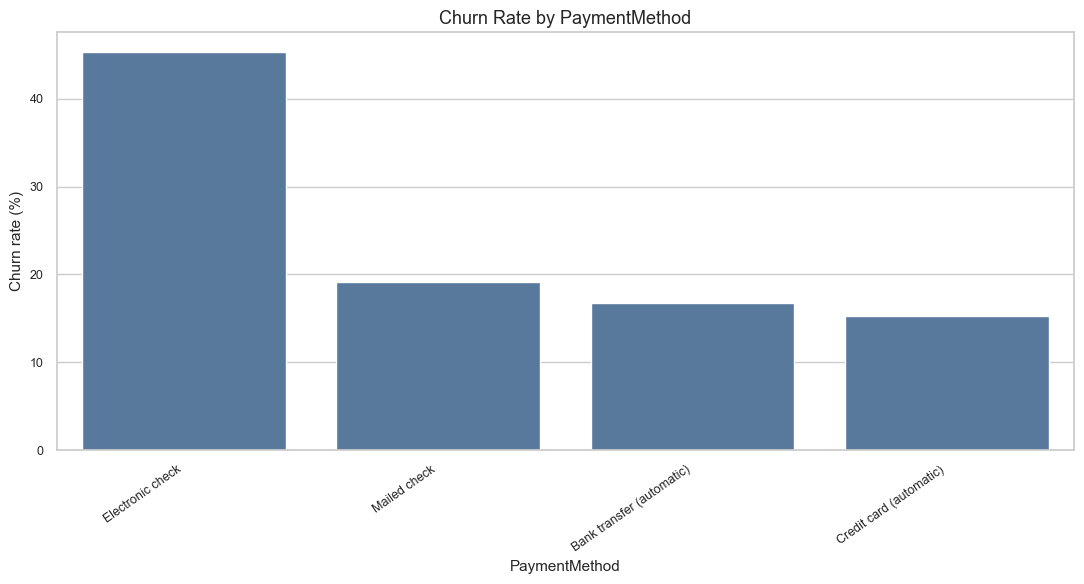

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_04_churn_rate_by_internet_service.png


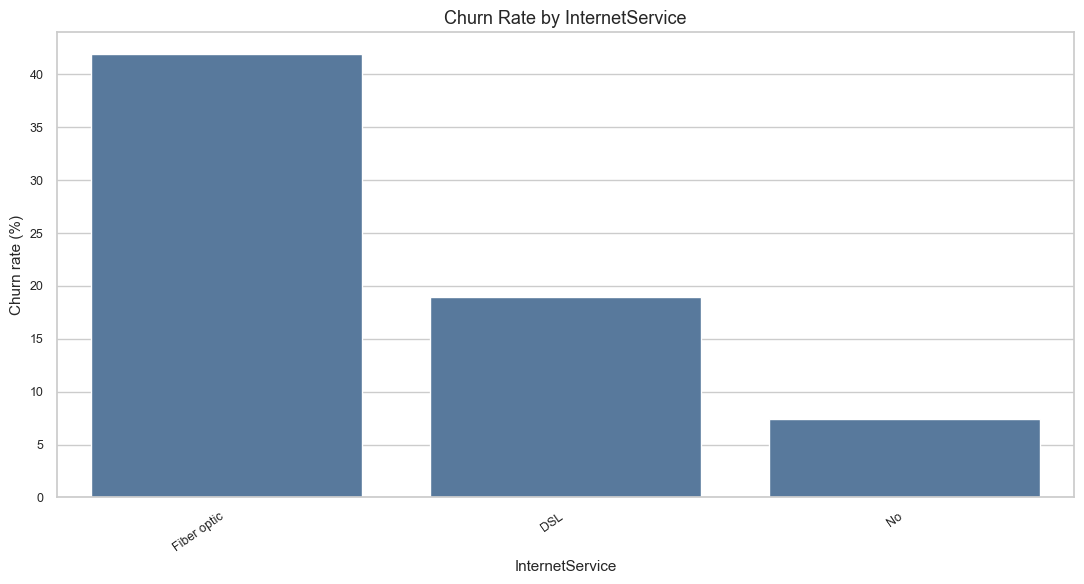

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_05_churn_rate_by_tenure_group.png


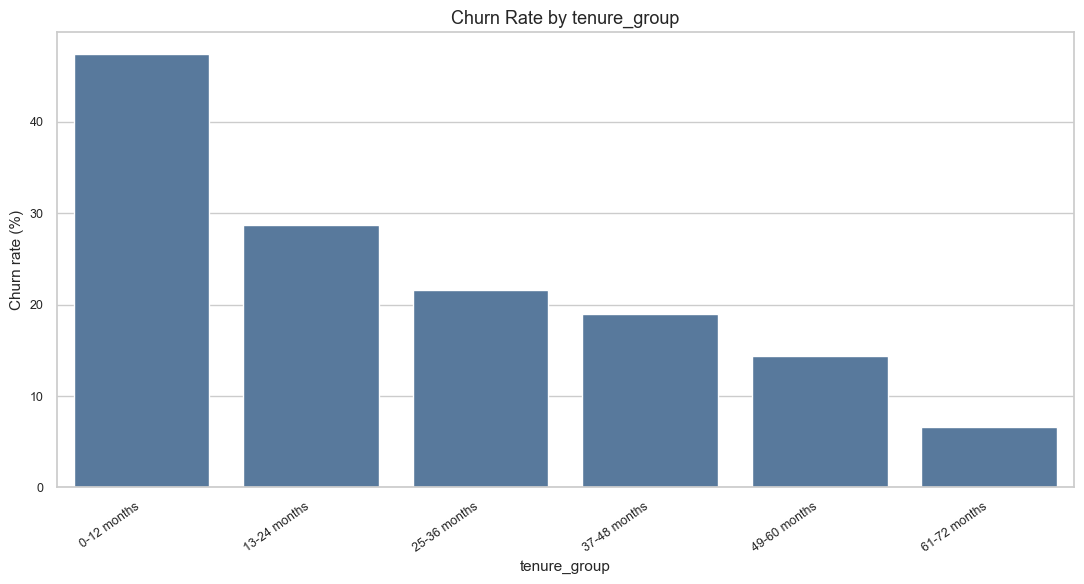

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_06_churn_rate_by_service_diversity.png


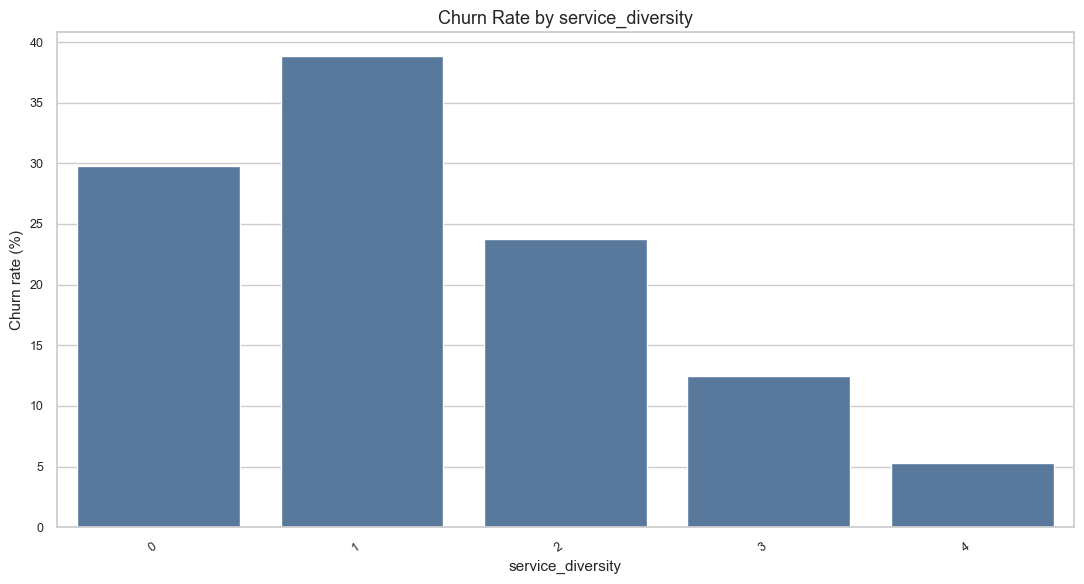

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_07_churn_rate_by_tech_support.png


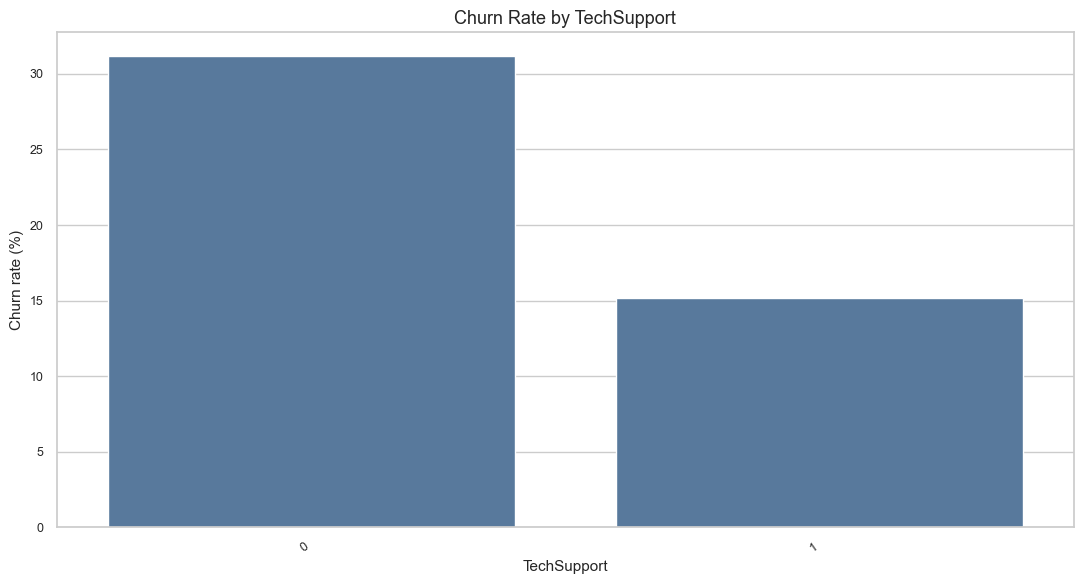

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_08_churn_rate_by_online_security.png


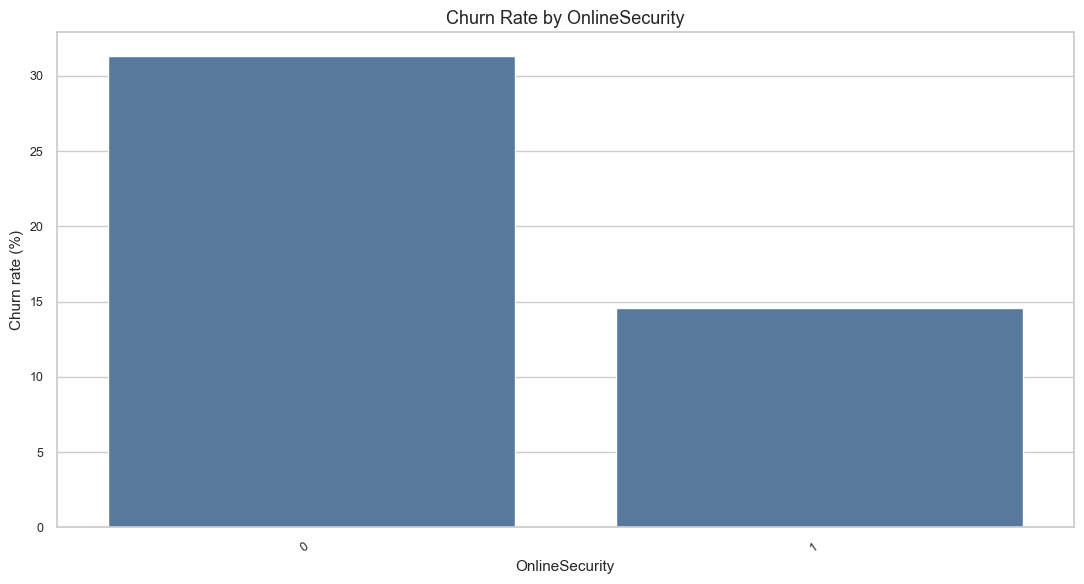

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_15_churn_rate_by_paperless_billing.png


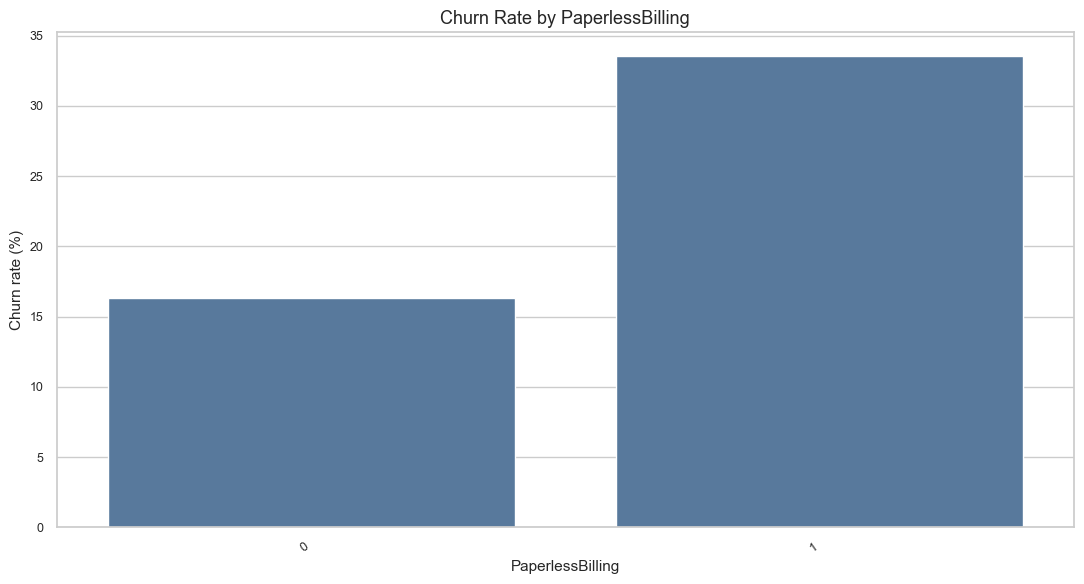

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_16_churn_rate_by_senior_citizen.png


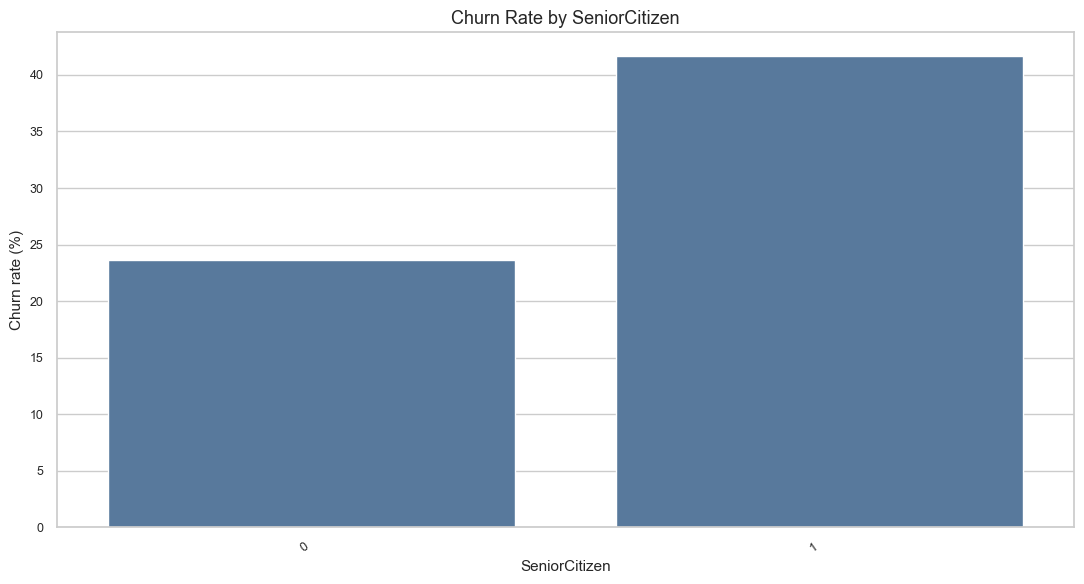

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_17_churn_rate_by_partner.png


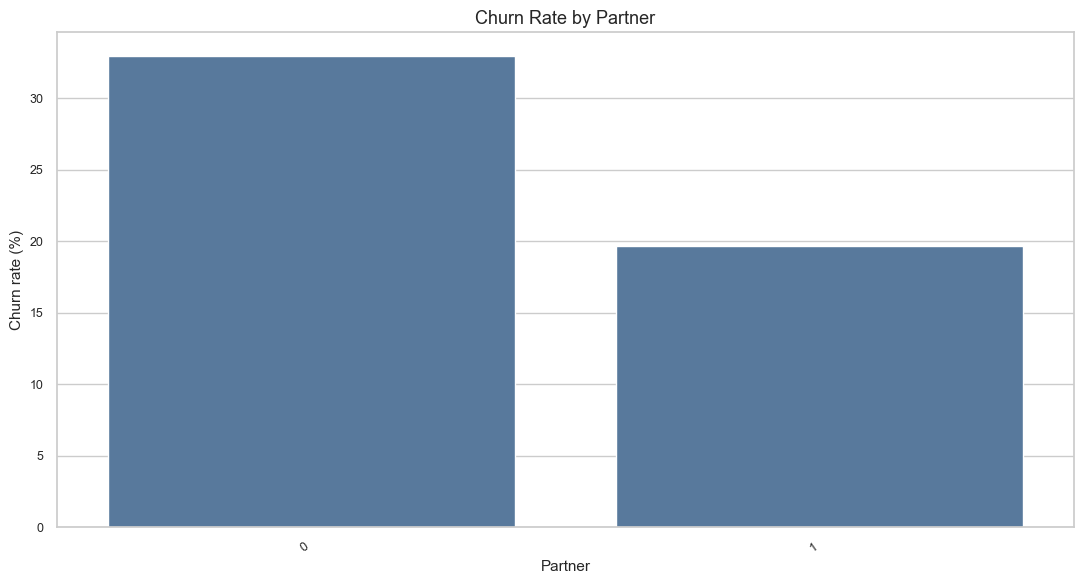

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_18_churn_rate_by_dependents.png


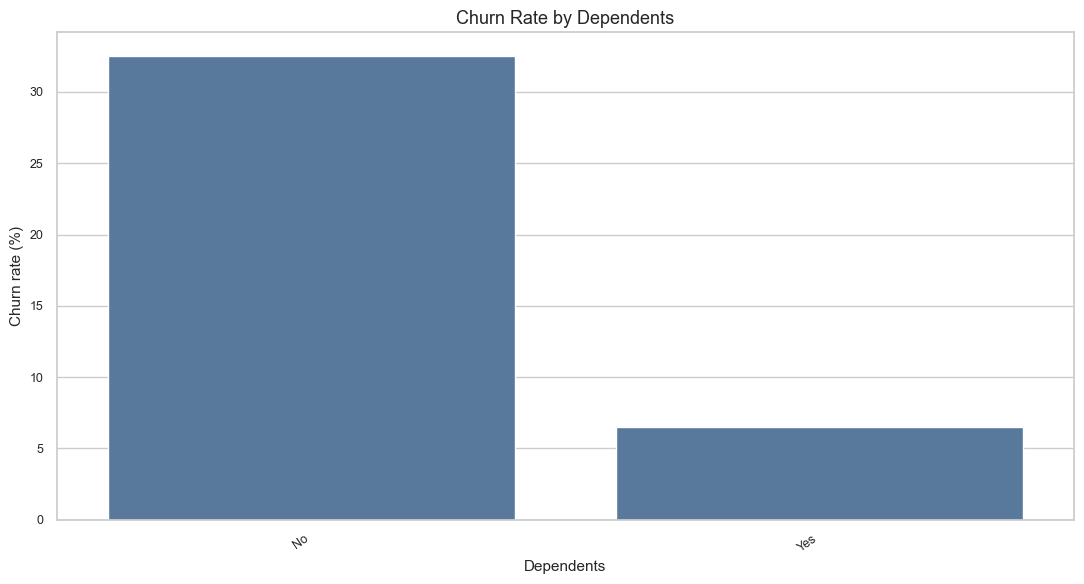

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/eda_18_churn_rate_by_dependents.png')

In [10]:
plot_churn_rate_bar("Contract", "Churn Rate by Contract Type", "eda_02_churn_rate_by_contract.png")
plot_churn_rate_bar("PaymentMethod", "Churn Rate by Payment Method", "eda_03_churn_rate_by_payment_method.png")
plot_churn_rate_bar("InternetService", "Churn Rate by Internet Service", "eda_04_churn_rate_by_internet_service.png")
plot_churn_rate_bar("tenure_group", "Churn Rate by Tenure Group", "eda_05_churn_rate_by_tenure_group.png")
plot_churn_rate_bar("service_diversity", "Churn Rate by Service Diversity Score", "eda_06_churn_rate_by_service_diversity.png")
plot_churn_rate_bar("TechSupport", "Churn Rate by Tech Support", "eda_07_churn_rate_by_tech_support.png")
plot_churn_rate_bar("OnlineSecurity", "Churn Rate by Online Security", "eda_08_churn_rate_by_online_security.png")
plot_churn_rate_bar("PaperlessBilling", "Churn Rate by Paperless Billing", "eda_15_churn_rate_by_paperless_billing.png")
plot_churn_rate_bar("SeniorCitizen", "Churn Rate by Senior Citizen", "eda_16_churn_rate_by_senior_citizen.png")
plot_churn_rate_bar("Partner", "Churn Rate by Partner", "eda_17_churn_rate_by_partner.png")
plot_churn_rate_bar("Dependents", "Churn Rate by Dependents", "eda_18_churn_rate_by_dependents.png")


Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_09_monthly_charges_distribution_by_churn.png


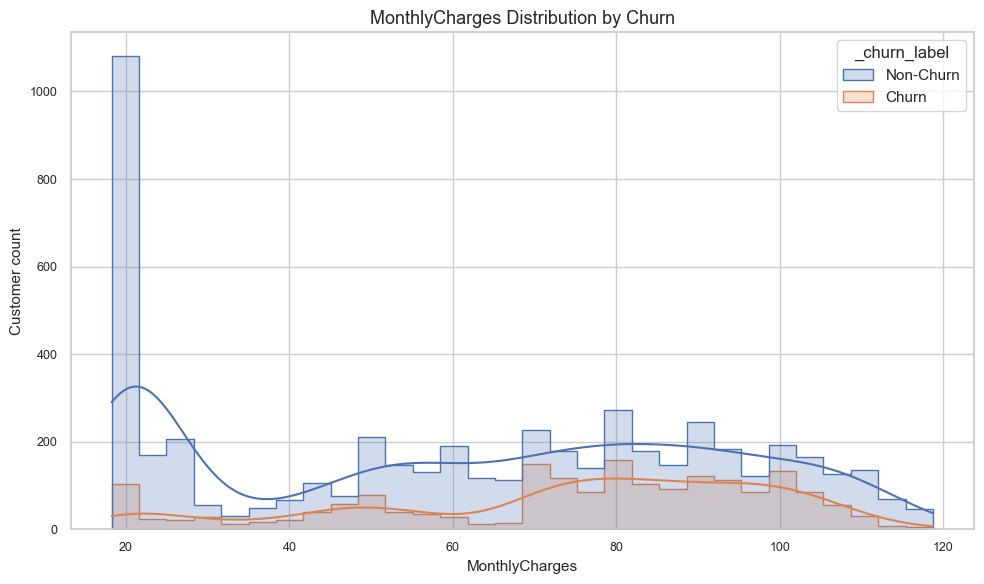

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_10_monthly_charges_boxplot_by_churn.png


C:\Users\HGB\AppData\Local\Temp\ipykernel_15112\1687174152.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=df_eda, x="_churn_label", y="MonthlyCharges", order=["Non-Churn", "Churn"], palette=["#59a14f", "#e15759"])


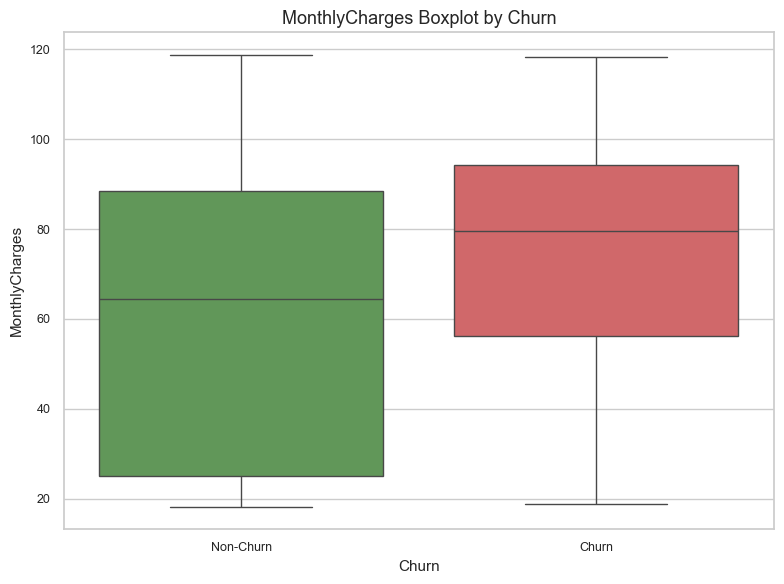

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_11_total_charges_boxplot_by_churn.png


C:\Users\HGB\AppData\Local\Temp\ipykernel_15112\1687174152.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=df_eda, x="_churn_label", y="TotalCharges", order=["Non-Churn", "Churn"], palette=["#59a14f", "#e15759"])


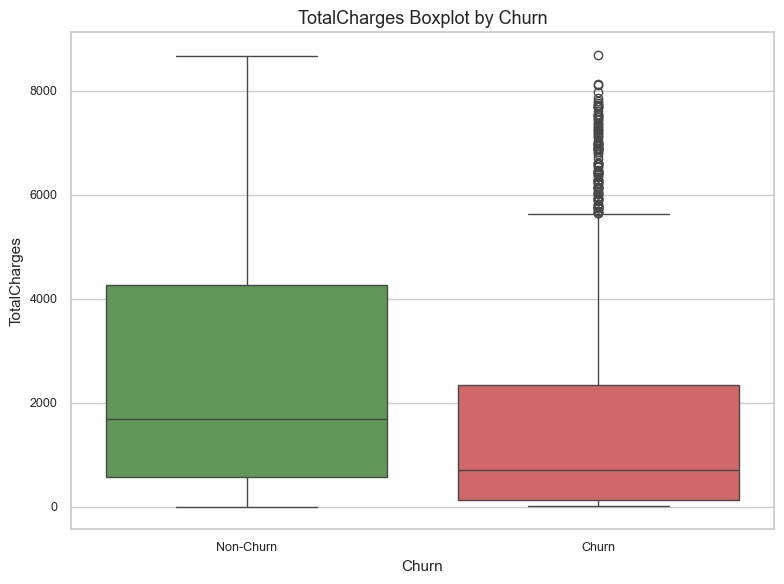

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_12_tenure_distribution_by_churn.png


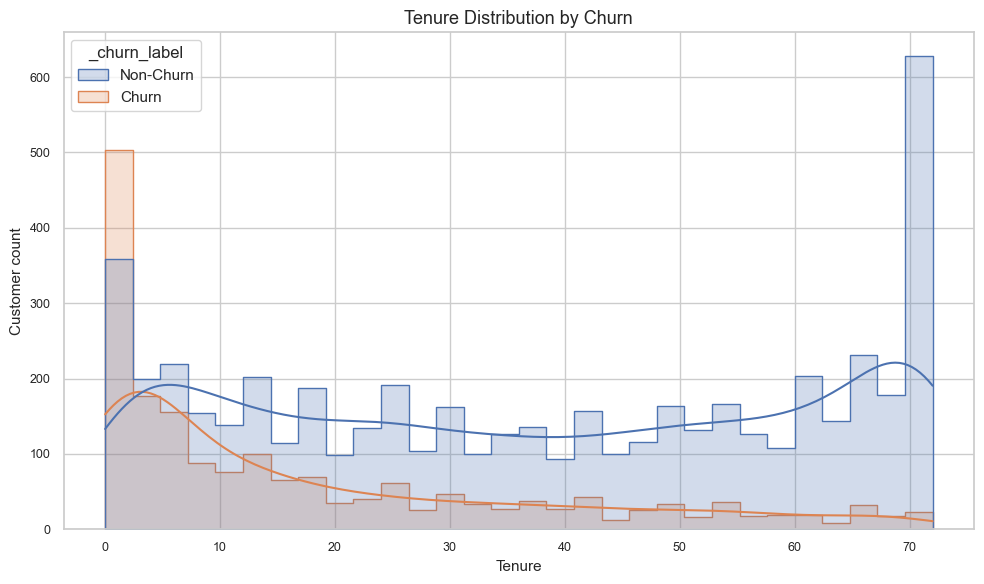

In [11]:
if has_columns(["MonthlyCharges"]):
    plt.figure(figsize=(10, 6))
    ax = sns.histplot(data=df_eda, x="MonthlyCharges", hue="_churn_label", bins=30, kde=True, element="step")
    ax.set_title("Monthly Charges Distribution by Churn")
    ax.set_xlabel(get_feature_display_name("MonthlyCharges"))
    ax.set_ylabel("Customer count")
    save_figure("eda_09_monthly_charges_distribution_by_churn.png")

if has_columns(["MonthlyCharges"]):
    plt.figure(figsize=(8, 6))
    ax = sns.boxplot(data=df_eda, x="_churn_label", y="MonthlyCharges", order=CHURN_LABEL_ORDER, palette=CHURN_PALETTE)
    ax.set_title("Monthly Charges Boxplot by Churn")
    ax.set_xlabel(get_feature_display_name("Churn"))
    ax.set_ylabel(get_feature_display_name("MonthlyCharges"))
    save_figure("eda_10_monthly_charges_boxplot_by_churn.png")

if has_columns(["TotalCharges"]):
    plt.figure(figsize=(8, 6))
    ax = sns.boxplot(data=df_eda, x="_churn_label", y="TotalCharges", order=CHURN_LABEL_ORDER, palette=CHURN_PALETTE)
    ax.set_title("Total Charges Boxplot by Churn")
    ax.set_xlabel(get_feature_display_name("Churn"))
    ax.set_ylabel(get_feature_display_name("TotalCharges"))
    save_figure("eda_11_total_charges_boxplot_by_churn.png")

if has_columns(["Tenure"]):
    plt.figure(figsize=(10, 6))
    ax = sns.histplot(data=df_eda, x="Tenure", hue="_churn_label", bins=30, kde=True, element="step")
    ax.set_title("Tenure Distribution by Churn")
    ax.set_xlabel(get_feature_display_name("Tenure"))
    ax.set_ylabel("Customer count")
    save_figure("eda_12_tenure_distribution_by_churn.png")


Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_13_correlation_heatmap.png


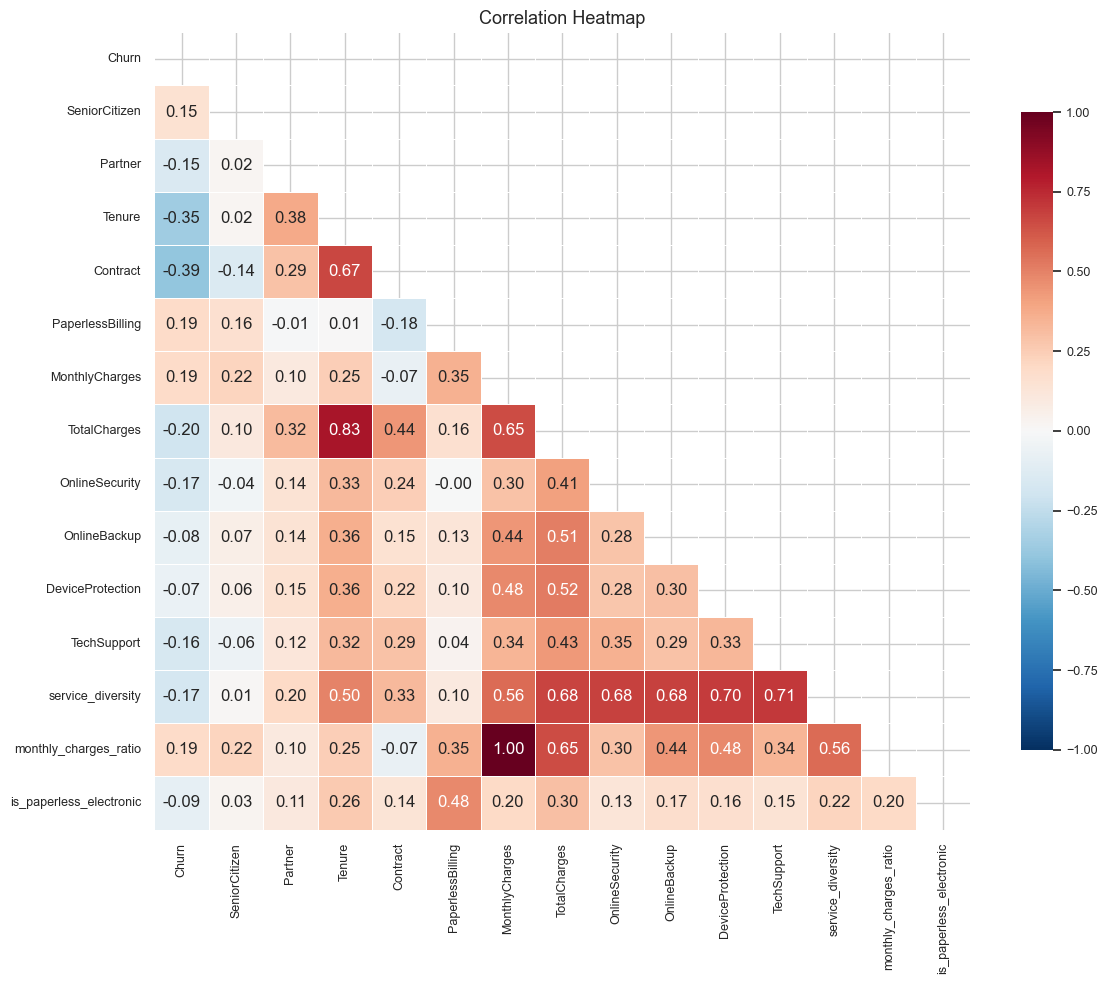

In [12]:
if "correlation_matrix" in globals():
    mask = np.triu(np.ones_like(correlation_display_matrix, dtype=bool))
    plt.figure(figsize=(12, 10))
    ax = sns.heatmap(
        correlation_display_matrix,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8},
    )
    ax.set_title("Correlation Heatmap")
    save_figure("eda_13_correlation_heatmap.png")
else:
    print("WARNING: correlation_matrix is unavailable; skipping correlation heatmap.")


Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_14_top_risk_segments.png


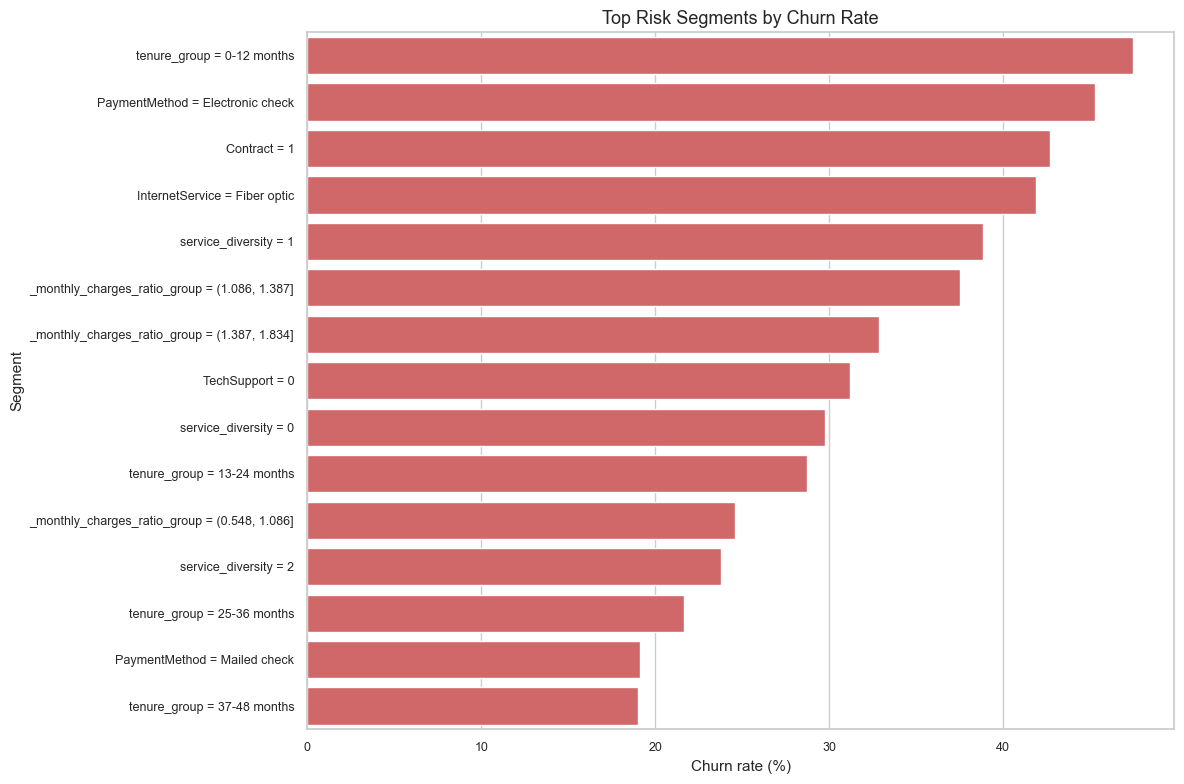

In [13]:
if "top_risk_segments" in globals() and not top_risk_segments.empty:
    plot_df = top_risk_segments.head(15).copy()
    if "feature_segment_display" not in plot_df.columns:
        plot_df["feature_segment_display"] = plot_df["feature"].astype(str) + " = " + plot_df["segment"].astype(str)
    plt.figure(figsize=(12, 8))
    ax = sns.barplot(data=plot_df, x="churn_rate_pct", y="feature_segment_display", color="#e15759")
    ax.set_title("Top Risk Segments by Churn Rate")
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("Segment")
    save_figure("eda_14_top_risk_segments.png")
else:
    print("WARNING: top_risk_segments is unavailable; skipping top risk segments chart.")


Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_19_contract_payment_method_churn_heatmap.png


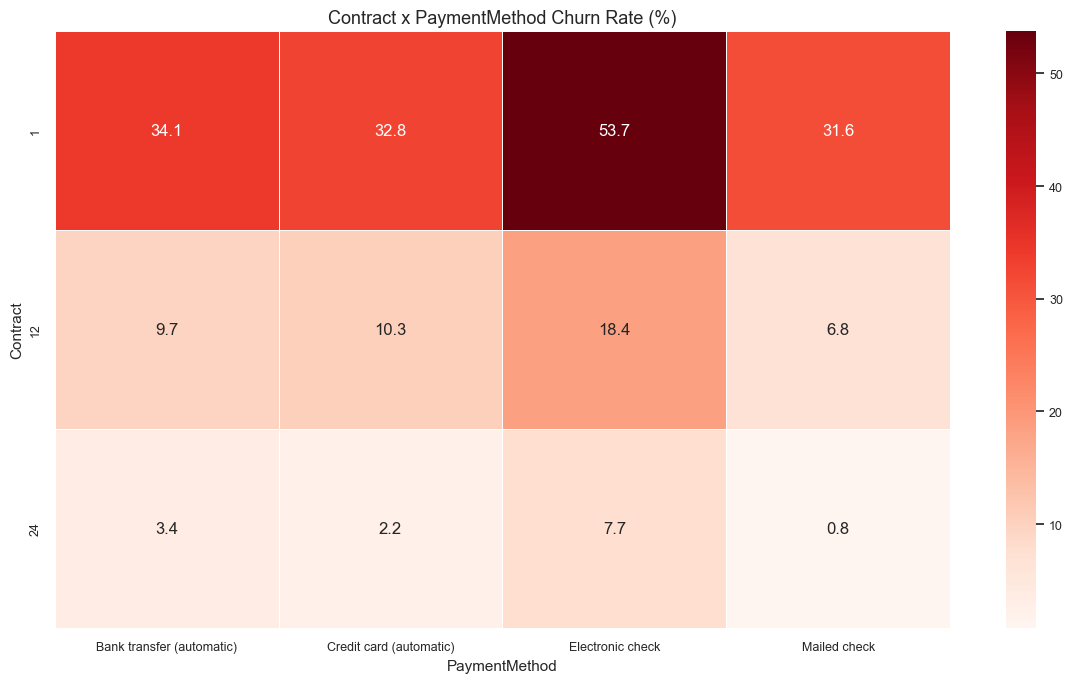

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_20_internet_service_tech_support_churn_heatmap.png


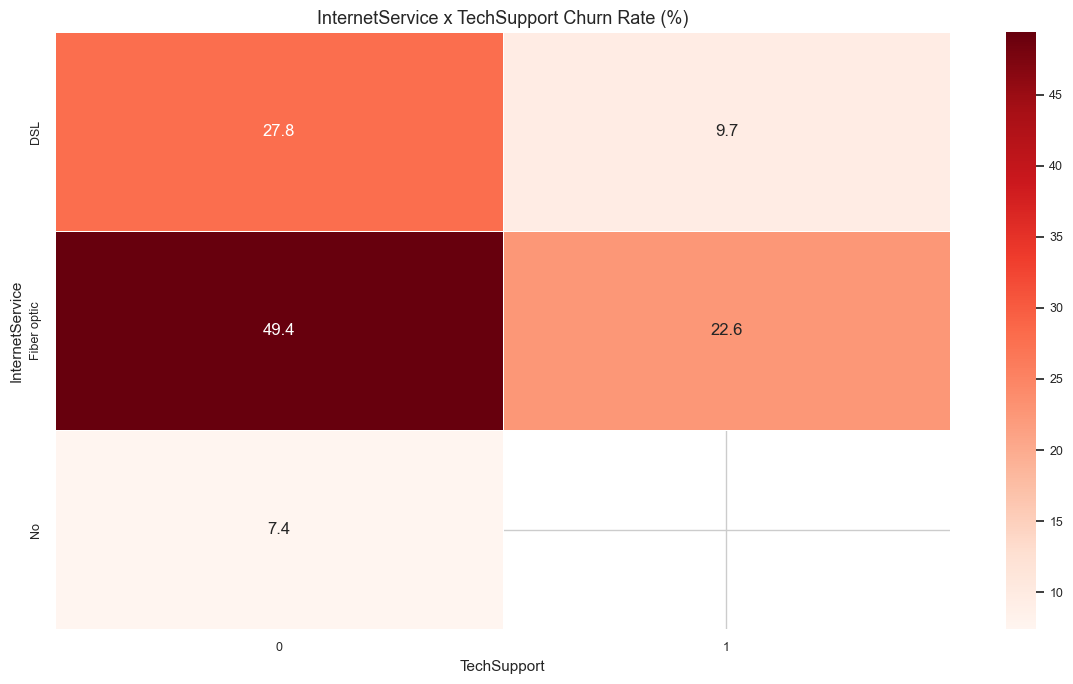

Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_21_tenure_group_contract_churn_heatmap.png


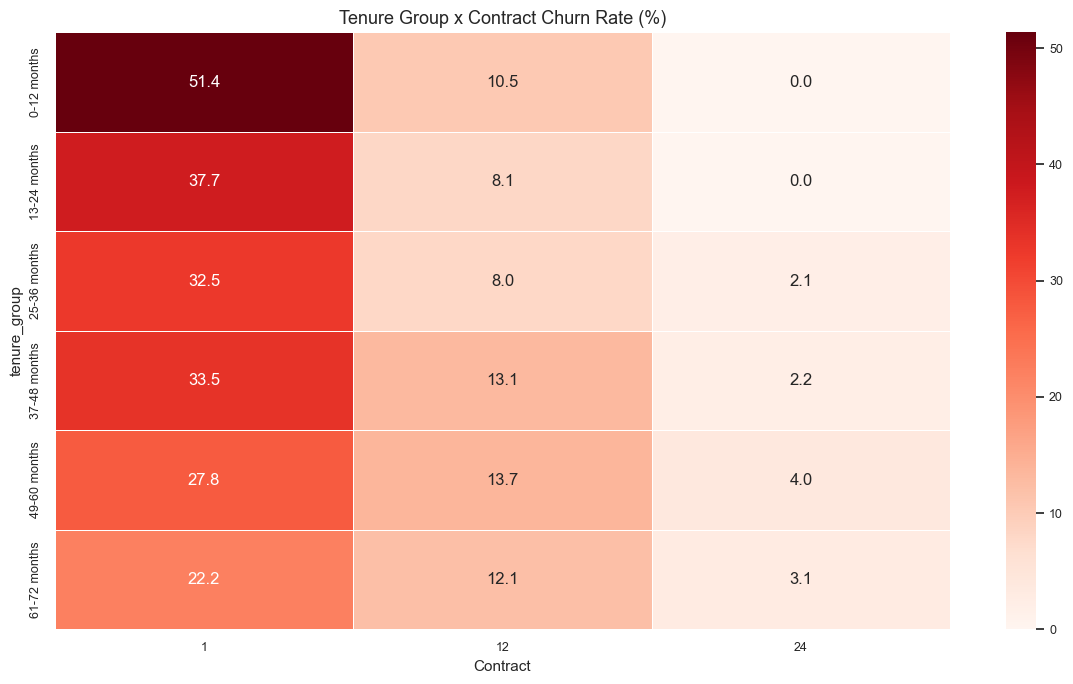

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/eda_21_tenure_group_contract_churn_heatmap.png')

In [14]:
plot_churn_rate_heatmap("Contract", "PaymentMethod", "Contract Type x Payment Method Churn Rate (%)", "eda_19_contract_payment_method_churn_heatmap.png")
plot_churn_rate_heatmap("InternetService", "TechSupport", "Internet Service x Tech Support Churn Rate (%)", "eda_20_internet_service_tech_support_churn_heatmap.png")
plot_churn_rate_heatmap("tenure_group", "Contract", "Tenure Group x Contract Type Churn Rate (%)", "eda_21_tenure_group_contract_churn_heatmap.png")


Saved figure path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\eda_22_monthly_charges_vs_tenure_by_churn.png


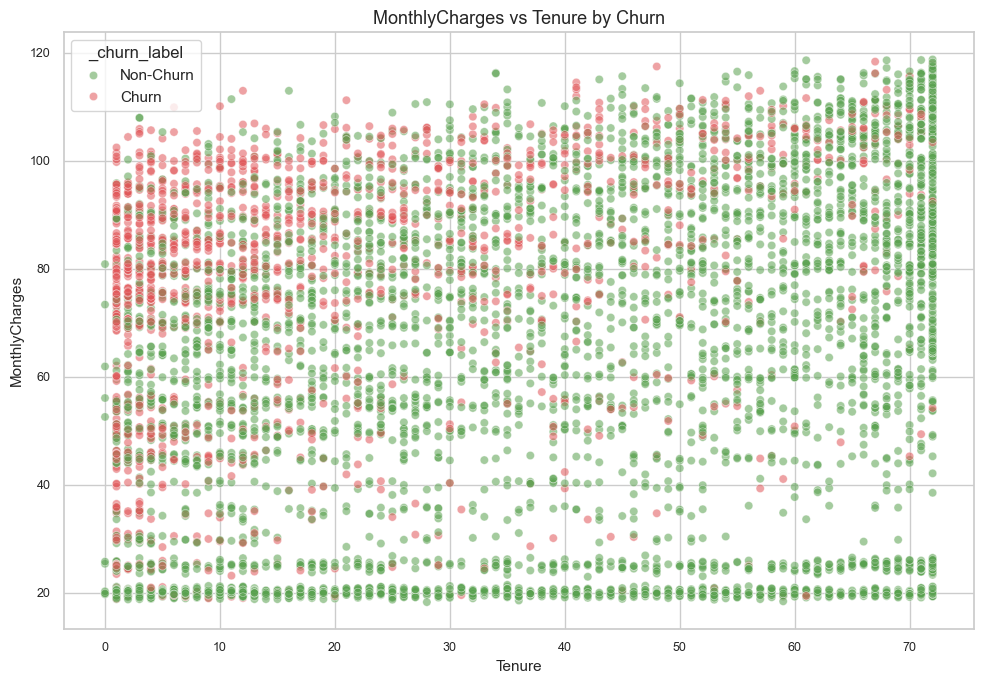

In [15]:
if has_columns(["MonthlyCharges", "Tenure"]):
    plt.figure(figsize=(10, 7))
    ax = sns.scatterplot(
        data=df_eda,
        x="Tenure",
        y="MonthlyCharges",
        hue="_churn_label",
        alpha=0.55,
        palette=CHURN_PALETTE,
    )
    ax.set_title("Monthly Charges vs Tenure by Churn")
    ax.set_xlabel(get_feature_display_name("Tenure"))
    ax.set_ylabel(get_feature_display_name("MonthlyCharges"))
    save_figure("eda_22_monthly_charges_vs_tenure_by_churn.png")


## Notes

This notebook does not create `EDA_data.csv`, does not run ingestion, does not connect to a database, and does not train models. Missing optional columns are handled by printing warnings and skipping only dependent outputs.
